# Experimentos integrales para detección de spambots con grafos

Esta notebook ejecuta auditoría de datos, features dirigidas, self-loops, centralidad/intermediación, comparación de modelos y comprobación de disponibilidad temporal.

## Uso
1. Colocá esta notebook en la raíz del repositorio `proyecto_botnet`.
2. Ejecutá **Run All** con el entorno virtual del proyecto.
3. Revisá la carpeta `reports/`.
4. Subí la notebook ejecutada y los CSV generados para analizar todo en conjunto.

## Precauciones
- `label` se usa como objetivo, nunca como predictor.
- Las métricas estructurales de la red completa son exploratorias: pueden incorporar conexiones de cuentas del conjunto de test.
- Una evaluación *point-in-time* real requiere timestamps de interacciones y un instante de corte explícito. Si no están, la notebook informa la limitación.
- Los self-loops se excluyen de la topología entre cuentas y se conservan como features independientes.


In [5]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

SEED = 42

# 1. DETECCIÓN AUTOMÁTICA DE LA RAÍZ DEL PROYECTO
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

# 2. DEFINICIÓN DE RUTAS ABSOLUTAS DINÁMICAS
BASE = PROJECT_ROOT / "data" / "processed"
RAW = PROJECT_ROOT / "data" / "raw"
REPORTS = PROJECT_ROOT / "notebooks" / "reports" if (PROJECT_ROOT / "notebooks" / "reports").exists() else PROJECT_ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

EDGE_PATH = BASE / "graph_weighted_edges.csv"
NODE_PATH = BASE / "graph_weighted_node_features.csv"
COMMUNITY_PATH = BASE / "graph_communities.csv"

# 3. VERIFICACIÓN Y CARGA
if not EDGE_PATH.exists() or not NODE_PATH.exists():
    raise FileNotFoundError(f"No se encontraron los CSV en la ruta esperada: {BASE}")

edges = pd.read_csv(EDGE_PATH)
nodes = pd.read_csv(NODE_PATH)
assert {"source","target","relation","weight"}.issubset(edges.columns)
assert {"user_id","label"}.issubset(nodes.columns)

edges["source"] = pd.to_numeric(edges["source"], errors="raise").astype("int64")
edges["target"] = pd.to_numeric(edges["target"], errors="raise").astype("int64")
edges["weight"] = pd.to_numeric(edges["weight"], errors="raise")
nodes["user_id"] = pd.to_numeric(nodes["user_id"], errors="raise").astype("int64")

if nodes["user_id"].duplicated().any():
    raise ValueError("user_id duplicados en el archivo de nodos")

print("✅ Rutas vinculadas correctamente desde:", PROJECT_ROOT)
print("Python:", sys.version)
print("Edges:", edges.shape, "| Nodes:", nodes.shape)
print("Labels:", nodes["label"].value_counts(dropna=False).to_dict())
print("Relations:", edges["relation"].value_counts(dropna=False).to_dict())
print("Missing weights:", int(edges["weight"].isna().sum()))
print("Negative weights:", int((edges["weight"] < 0).sum()))
print("Unknown sources:", int((~edges["source"].isin(nodes["user_id"])).sum()))
print("Unknown targets:", int((~edges["target"].isin(nodes["user_id"])).sum()))

✅ Rutas vinculadas correctamente desde: /home/adalisa/Documentos/proyectos_git/proyecto_botnet
Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Edges: (4404, 4) | Nodes: (4465, 5)
Labels: {0: 3474, 1: 991}
Relations: {'mention': 2577, 'reply': 1827}
Missing weights: 0
Negative weights: 0
Unknown sources: 0
Unknown targets: 0


## 1. Auditoría de self-loops y relaciones

In [6]:
self_loops = edges[edges.source == edges.target].copy()
nonloops = edges[edges.source != edges.target].copy()

loop_by_label = (self_loops.merge(nodes[["user_id","label"]], left_on="source", right_on="user_id", how="left")
    .groupby("label", dropna=False)
    .agg(accounts=("source","nunique"), rows=("weight","size"),
         weight_sum=("weight","sum"), weight_mean=("weight","mean")).reset_index())
display(loop_by_label)
loop_by_label.to_csv(REPORTS / "self_loops_by_label.csv", index=False)

relation_audit = edges.groupby("relation").apply(
    lambda d: pd.Series({
        "rows": len(d), "unique_sources": d.source.nunique(),
        "unique_targets": d.target.nunique(), "weight_total": d.weight.sum(),
        "self_loop_rows": int((d.source == d.target).sum())
    }), include_groups=False
).reset_index()
display(relation_audit)
relation_audit.to_csv(REPORTS / "relation_direction_audit.csv", index=False)

print("Total edge rows:", len(edges))
print("Self-loop rows:", len(self_loops))
print("Self-loop weight:", self_loops.weight.sum())
print("Distinct accounts with self-loops:", self_loops.source.nunique())


,label,accounts,rows,weight_sum,weight_mean
0,0,946,946,23649,24.998943
1,1,30,30,353,11.766667


,relation,rows,unique_sources,unique_targets,weight_total,self_loop_rows
0,mention,2577,976,580,10416,0
1,reply,1827,1418,1210,29853,976


Total edge rows: 4404
Self-loop rows: 976
Self-loop weight: 24002
Distinct accounts with self-loops: 976


## 2. Features de interacción dirigidas, balance entrada/salida y self-loops

In [7]:
# edge_count cuenta filas del CSV agregadas; weight suma el peso entregado por la fuente.
# No se asume que weight sea el número bruto de mensajes.
feature_table = pd.DataFrame({"user_id": nodes.user_id})

for relation in sorted(edges.relation.dropna().unique()):
    rel = nonloops[nonloops.relation == relation]
    out = rel.groupby("source").agg(
        **{f"{relation}_out_edge_count": ("weight","size"),
           f"{relation}_out_weight": ("weight","sum")}).rename_axis("user_id")
    inc = rel.groupby("target").agg(
        **{f"{relation}_in_edge_count": ("weight","size"),
           f"{relation}_in_weight": ("weight","sum")}).rename_axis("user_id")
    feature_table = feature_table.merge(out, on="user_id", how="left").merge(inc, on="user_id", how="left")

loops = self_loops.groupby("source").agg(
    self_loop_count=("weight","size"), self_loop_weight=("weight","sum")).rename_axis("user_id").reset_index()
feature_table = feature_table.merge(loops, left_on="user_id", right_on="user_id", how="left")
feature_table["has_self_loop"] = feature_table["self_loop_count"].fillna(0).gt(0).astype(int)
feature_table = feature_table.fillna(0)

count_cols = [c for c in feature_table.columns if c.endswith("_edge_count") or c == "self_loop_count"]
for c in count_cols:
    feature_table[c] = feature_table[c].astype("int64")

for relation in sorted(nonloops.relation.dropna().unique()):
    for metric in ["edge_count","weight"]:
        inc, out = f"{relation}_in_{metric}", f"{relation}_out_{metric}"
        feature_table[f"{relation}_in_minus_out_{metric}"] = feature_table[inc] - feature_table[out]
        feature_table[f"{relation}_in_out_{metric}_ratio"] = feature_table[inc] / (feature_table[out] + 1.0)

in_counts = [c for c in feature_table if c.endswith("_in_edge_count")]
out_counts = [c for c in feature_table if c.endswith("_out_edge_count")]
in_weights = [c for c in feature_table if c.endswith("_in_weight")]
out_weights = [c for c in feature_table if c.endswith("_out_weight")]
feature_table["all_in_edge_count"] = feature_table[in_counts].sum(axis=1)
feature_table["all_out_edge_count"] = feature_table[out_counts].sum(axis=1)
feature_table["all_in_weight"] = feature_table[in_weights].sum(axis=1)
feature_table["all_out_weight"] = feature_table[out_weights].sum(axis=1)
feature_table["in_minus_out_count"] = feature_table.all_in_edge_count - feature_table.all_out_edge_count
feature_table["in_out_count_ratio"] = feature_table.all_in_edge_count / (feature_table.all_out_edge_count + 1.0)
feature_table["in_minus_out_weight"] = feature_table.all_in_weight - feature_table.all_out_weight
feature_table["in_out_weight_ratio"] = feature_table.all_in_weight / (feature_table.all_out_weight + 1.0)

directed_features = nodes[["user_id","label"]].merge(feature_table, on="user_id", how="left", validate="one_to_one")
directed_features.to_csv(BASE / "graph_directed_features_experimental.csv", index=False)
display(directed_features.head())
print("Features guardadas:", BASE / "graph_directed_features_experimental.csv")


,user_id,label,mention_out_edge_count,mention_out_weight,mention_in_edge_count,mention_in_weight,reply_out_edge_count,reply_out_weight,reply_in_edge_count,reply_in_weight,...,reply_in_minus_out_weight,reply_in_out_weight_ratio,all_in_edge_count,all_out_edge_count,all_in_weight,all_out_weight,in_minus_out_count,in_out_count_ratio,in_minus_out_weight,in_out_weight_ratio
0,466305031,1,5,5.0,0,0.0,1,1.0,0,0.0,...,-1.0,0.000000,0,0,0.0,0.0,0,0.000000,0.0,0.000000
1,466255887,1,1,2.0,0,0.0,1,2.0,0,0.0,...,-2.0,0.000000,0,0,0.0,0.0,0,0.000000,0.0,0.000000
2,1902706704,0,5,10.0,1,18.0,1,41.0,0,0.0,...,-41.0,0.000000,1,1,18.0,18.0,0,0.500000,0.0,0.947368
3,466124818,1,0,0.0,0,0.0,0,0.0,0,0.0,...,0.0,0.000000,0,0,0.0,0.0,0,0.000000,0.0,0.000000
4,19759124,0,6,64.0,5,60.0,5,38.0,3,40.0,...,2.0,1.025641,8,8,100.0,100.0,0,0.888889,0.0,0.990099


Features guardadas: /home/adalisa/Documentos/proyectos_git/proyecto_botnet/data/processed/graph_directed_features_experimental.csv


## 3. Grafo dirigido: intermediación, PageRank, reciprocidad y balance

`betweenness` aproxima qué tan frecuentemente una cuenta aparece en caminos mínimos; es una proxy de intermediación, no prueba por sí misma que la información haya pasado por esa cuenta. Se calcula sin self-loops. Las métricas usan el grafo completo disponible y solo serían históricas si el archivo ya estuviera cortado en un instante conocido.


In [8]:
G = nx.DiGraph()
G.add_nodes_from(nodes.user_id.astype(int))
pair_weights = nonloops.groupby(["source","target"], as_index=False).weight.sum()
G.add_weighted_edges_from((int(r.source), int(r.target), float(r.weight)) for r in pair_weights.itertuples(index=False))

in_deg, out_deg = dict(G.in_degree()), dict(G.out_degree())
in_strength, out_strength = dict(G.in_degree(weight="weight")), dict(G.out_degree(weight="weight"))
# Approximation by sampling for efficiency/reproducibility.
betweenness = nx.betweenness_centrality(G, k=min(500, G.number_of_nodes()), normalized=True, seed=SEED)
pagerank = nx.pagerank(G, weight="weight")
reciprocity = {}
for u in G.nodes:
    succ = list(G.successors(u))
    reciprocity[u] = sum(G.has_edge(v, u) for v in succ) / len(succ) if succ else 0.0

structural = pd.DataFrame({
    "user_id": list(G.nodes),
    "in_degree_distinct": [in_deg[u] for u in G.nodes],
    "out_degree_distinct": [out_deg[u] for u in G.nodes],
    "in_strength": [in_strength[u] for u in G.nodes],
    "out_strength": [out_strength[u] for u in G.nodes],
    "in_minus_out_degree": [in_deg[u]-out_deg[u] for u in G.nodes],
    "in_out_degree_ratio": [in_deg[u]/(out_deg[u]+1) for u in G.nodes],
    "in_minus_out_strength": [in_strength[u]-out_strength[u] for u in G.nodes],
    "in_out_strength_ratio": [in_strength[u]/(out_strength[u]+1) for u in G.nodes],
    "betweenness_approx": [betweenness[u] for u in G.nodes],
    "pagerank": [pagerank[u] for u in G.nodes],
    "outgoing_reciprocity": [reciprocity[u] for u in G.nodes],
})
structural = nodes[["user_id","label"]].merge(structural, on="user_id", how="left", validate="one_to_one")
structural.to_csv(BASE / "graph_structural_features_directed.csv", index=False)
display(structural.groupby("label").mean(numeric_only=True).round(4))
print("Grafo dirigido:", G.number_of_nodes(), "nodos,", G.number_of_edges(), "aristas sin self-loops")


,user_id,in_degree_distinct,out_degree_distinct,in_strength,out_strength,in_minus_out_degree,in_out_degree_ratio,in_minus_out_strength,in_out_strength_ratio,betweenness_approx,pagerank,outgoing_reciprocity
label,,,,,,,,,,,,
0,9.519675e+08,0.2044,0.2041,3.8166,3.8164,0.0003,0.1593,0.0003,2.0340,0.0,0.0002,0.0204
1,6.490490e+08,1.8991,1.9001,3.0353,3.0363,-0.0010,0.7399,-0.0010,0.8615,0.0,0.0004,0.0078


Grafo dirigido: 4465 nodos, 2592 aristas sin self-loops


## 4. Distribuciones por etiqueta

,feature,label,n,zero_fraction,mean,median,q90,q99
0,mention_out_edge_count,0,3474,0.888313,0.200058,0.0,1.000000,4.000000
1,mention_out_edge_count,1,991,0.406660,1.899092,1.0,5.000000,14.000000
2,mention_out_weight,0,3474,0.888313,2.303972,0.0,1.000000,58.270000
3,mention_out_weight,1,991,0.406660,2.433905,1.0,6.000000,25.000000
4,mention_in_edge_count,0,3474,0.882268,0.200058,0.0,1.000000,3.000000
5,mention_in_edge_count,1,991,0.827447,1.899092,0.0,1.000000,41.100000
6,mention_in_weight,0,3474,0.882268,2.303972,0.0,1.000000,61.620000
7,mention_in_weight,1,991,0.827447,2.433905,0.0,1.000000,57.600000
8,reply_out_edge_count,0,3474,0.931779,0.107369,0.0,0.000000,2.000000
9,reply_out_edge_count,1,991,0.557013,0.482341,0.0,1.000000,2.000000


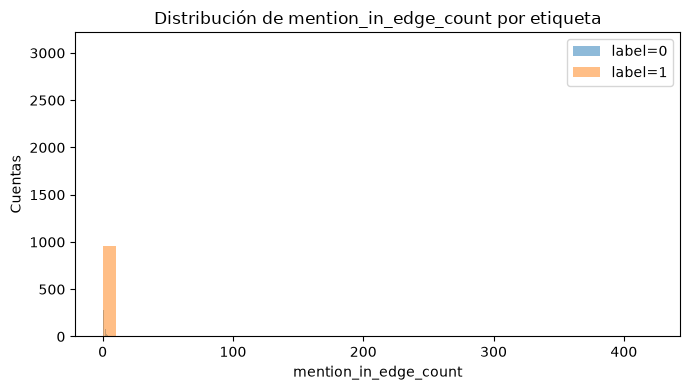

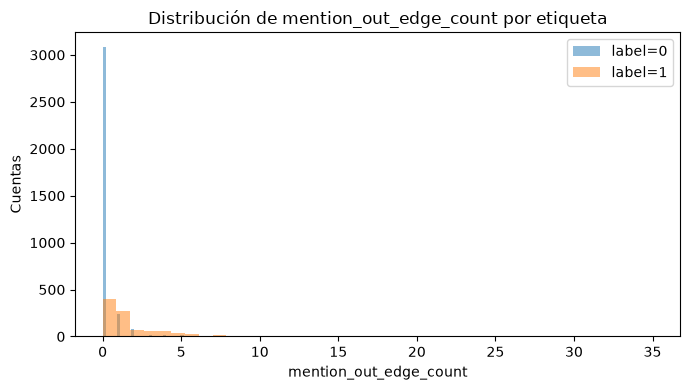

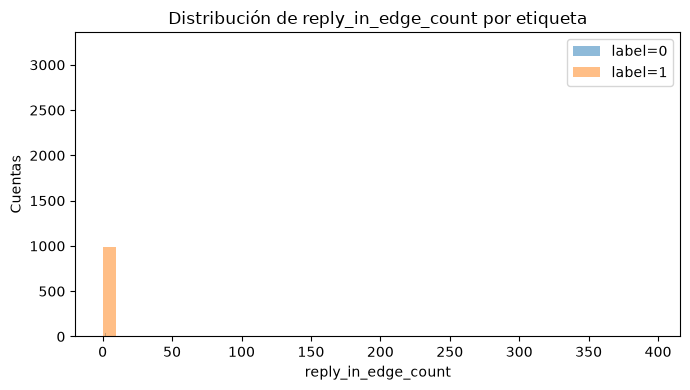

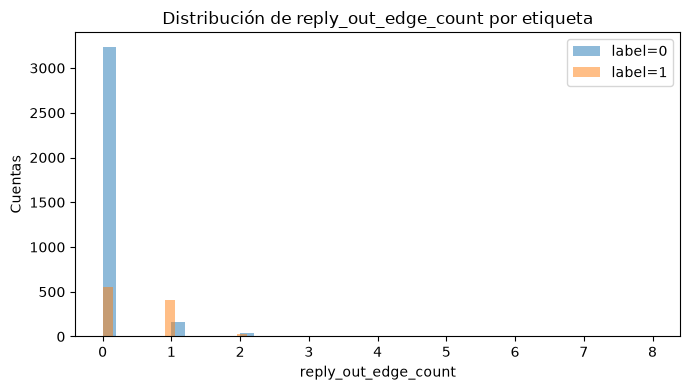

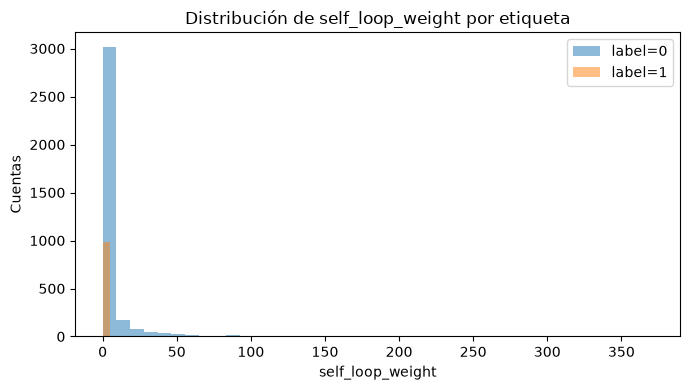

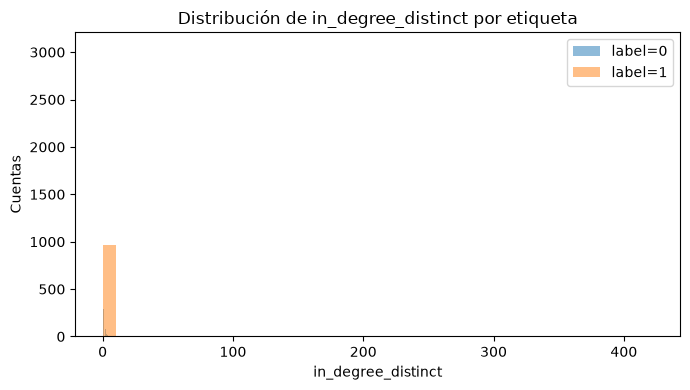

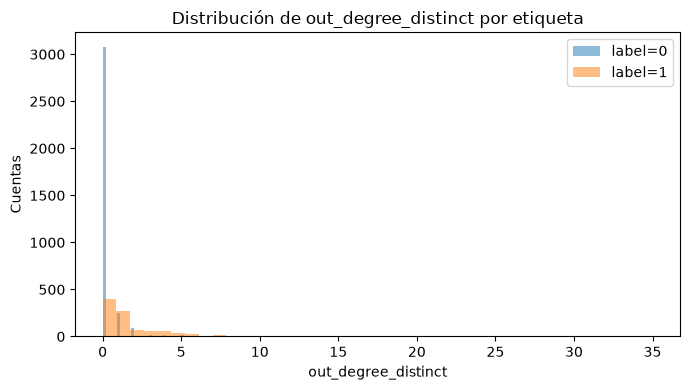

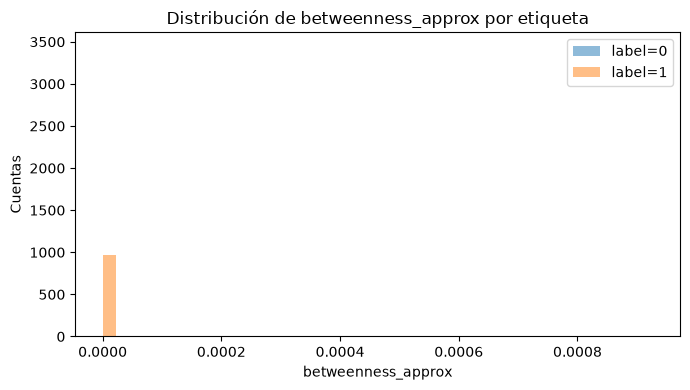

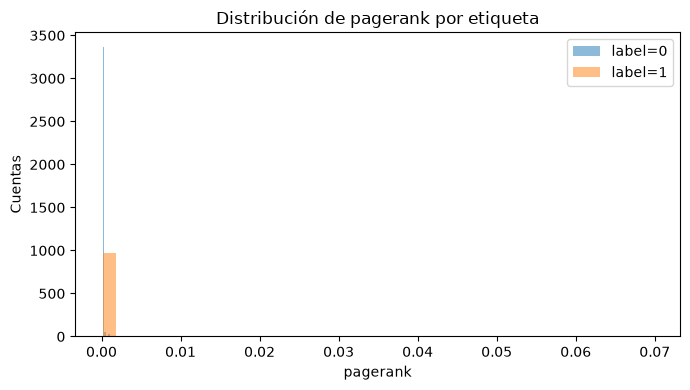

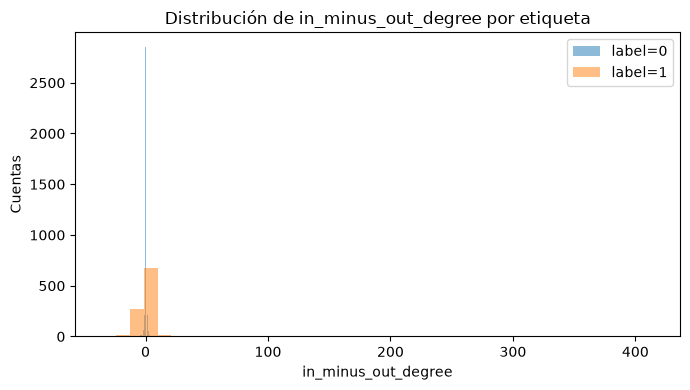

In [9]:
analysis = directed_features.merge(structural.drop(columns=["label"]), on="user_id", how="left", validate="one_to_one")
feature_cols = [c for c in analysis.columns if c not in {"user_id","label"} and pd.api.types.is_numeric_dtype(analysis[c])]

dist_rows = []
for col in feature_cols:
    for label, grp in analysis.groupby("label"):
        dist_rows.append({
            "feature": col, "label": label, "n": len(grp),
            "zero_fraction": (grp[col] == 0).mean(), "mean": grp[col].mean(),
            "median": grp[col].median(), "q90": grp[col].quantile(.90),
            "q99": grp[col].quantile(.99)
        })
distribution = pd.DataFrame(dist_rows)
distribution.to_csv(REPORTS / "feature_distribution_by_label.csv", index=False)
display(distribution.head(50))

for col in ["mention_in_edge_count","mention_out_edge_count","reply_in_edge_count","reply_out_edge_count",
            "self_loop_weight","in_degree_distinct","out_degree_distinct","betweenness_approx","pagerank","in_minus_out_degree"]:
    if col not in analysis: 
        continue
    plt.figure(figsize=(7,4))
    for label, grp in analysis.groupby("label"):
        plt.hist(grp[col].replace([np.inf,-np.inf],np.nan).dropna(), bins=40, alpha=.5, label=f"label={label}")
    plt.title(f"Distribución de {col} por etiqueta")
    plt.xlabel(col); plt.ylabel("Cuentas"); plt.legend(); plt.tight_layout(); plt.show()


## 5. Modelos y ablación de variables

Se comparan regresión logística, Random Forest y Extra Trees con tres conjuntos de features. Métricas principales: precision, recall, F1 y Average Precision (PR-AUC aproximada). La partición aleatoria es exploratoria: como la red se calcula con todas las aristas, puede existir fuga estructural; no debe considerarse una evaluación point-in-time.


In [10]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score, confusion_matrix

analysis = analysis.replace([np.inf,-np.inf], np.nan)
basic_cols = [c for c in directed_features.columns if c not in {"user_id","label"} and (
    c.endswith("_edge_count") or c.endswith("_weight") or c == "has_self_loop"
)]
direction_cols = basic_cols + [c for c in directed_features.columns if "minus_out" in c or "in_out_" in c]
structural_cols = direction_cols + [c for c in structural.columns if c not in {"user_id","label"}]
feature_sets = {
    "A_basic_interactions": list(dict.fromkeys(basic_cols)),
    "B_directionality": list(dict.fromkeys(direction_cols)),
    "C_graph_structure": list(dict.fromkeys(structural_cols)),
}
y = analysis["label"].astype(int).to_numpy()
train_idx, test_idx = train_test_split(np.arange(len(analysis)), test_size=.25, random_state=SEED, stratify=y)

models = {
    "LogisticRegression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "RandomForest": make_pipeline(SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "ExtraTrees": make_pipeline(SimpleImputer(strategy="median"),
        ExtraTreesClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
}

rows, pred_rows = [], []
for set_name, cols in feature_sets.items():
    cols = [c for c in cols if c in analysis.columns and c not in {"user_id","label"}]
    X = analysis[cols]
    Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
    ytr, yte = y[train_idx], y[test_idx]
    for model_name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        score = model.predict_proba(Xte)[:,1]
        cm = confusion_matrix(yte, pred, labels=[0,1])
        rows.append({
            "feature_set": set_name, "model": model_name, "n_features": len(cols),
            "precision_spambot": precision_score(yte,pred,zero_division=0),
            "recall_spambot": recall_score(yte,pred,zero_division=0),
            "f1_spambot": f1_score(yte,pred,zero_division=0),
            "average_precision": average_precision_score(yte,score),
            "roc_auc": roc_auc_score(yte,score),
            "tn": int(cm[0,0]), "fp": int(cm[0,1]), "fn": int(cm[1,0]), "tp": int(cm[1,1])
        })
        pred_rows.extend({
            "user_id": int(uid), "y_true": int(yt), "y_pred": int(yp),
            "score_spambot": float(sc), "feature_set": set_name, "model": model_name
        } for uid,yt,yp,sc in zip(analysis.iloc[test_idx].user_id, yte, pred, score))

model_results = pd.DataFrame(rows).sort_values(["average_precision","f1_spambot"], ascending=False)
display(model_results)
model_results.to_csv(REPORTS / "model_comparison_random_split.csv", index=False)
pd.DataFrame(pred_rows).to_csv(REPORTS / "test_predictions_random_split.csv", index=False)


,feature_set,model,n_features,precision_spambot,recall_spambot,f1_spambot,average_precision,roc_auc,tn,fp,fn,tp
7,C_graph_structure,RandomForest,37,0.901042,0.697581,0.786364,0.777191,0.882598,850,19,75,173
6,C_graph_structure,LogisticRegression,37,0.837321,0.705645,0.765864,0.776876,0.883406,835,34,73,175
8,C_graph_structure,ExtraTrees,37,0.882051,0.693548,0.776524,0.775246,0.881308,846,23,76,172
5,B_directionality,ExtraTrees,26,0.855000,0.689516,0.763393,0.775226,0.882860,840,29,77,171
2,A_basic_interactions,ExtraTrees,19,0.912088,0.669355,0.772093,0.774427,0.882712,853,16,82,166
4,B_directionality,RandomForest,26,0.842365,0.689516,0.758315,0.772892,0.880865,837,32,77,171
1,A_basic_interactions,RandomForest,19,0.842365,0.689516,0.758315,0.771596,0.881399,837,32,77,171
3,B_directionality,LogisticRegression,26,0.890052,0.685484,0.774487,0.771277,0.885338,848,21,78,170
0,A_basic_interactions,LogisticRegression,19,0.911602,0.665323,0.769231,0.770333,0.882809,853,16,83,165


## 6. Importancia de variables (Extra Trees)

,feature,importance
9,has_self_loop,0.217005
0,mention_out_edge_count,0.144318
27,out_degree_distinct,0.122252
4,reply_out_edge_count,0.099489
12,reply_in_minus_out_edge_count,0.056568
10,mention_in_minus_out_edge_count,0.052337
30,in_minus_out_degree,0.044073
8,self_loop_weight,0.029764
1,mention_out_weight,0.026452
29,out_strength,0.022217


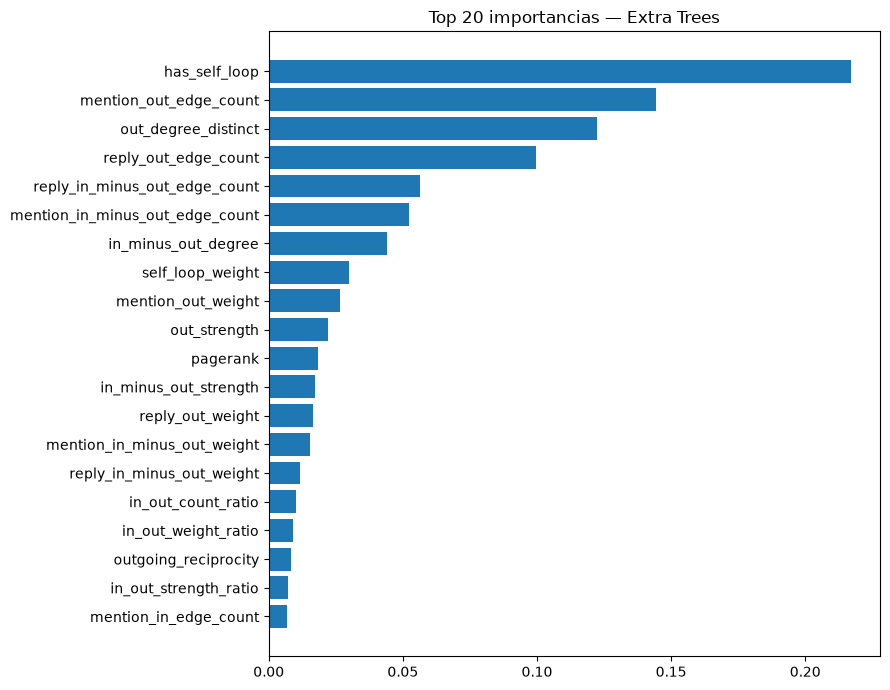

In [11]:
cols = [c for c in feature_sets["C_graph_structure"] if c in analysis.columns and c not in {"user_id","label"}]
X = analysis[cols]
Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
imp = make_pipeline(SimpleImputer(strategy="median"),
    ExtraTreesClassifier(n_estimators=400, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=-1))
imp.fit(Xtr, y[train_idx])
tree = imp[-1]
importance = pd.DataFrame({"feature": cols, "importance": tree.feature_importances_}).sort_values("importance", ascending=False)
display(importance.head(30))
importance.to_csv(REPORTS / "feature_importance_extratrees.csv", index=False)
top = importance.head(20).sort_values("importance")
plt.figure(figsize=(9,7)); plt.barh(top.feature, top.importance)
plt.title("Top 20 importancias — Extra Trees"); plt.tight_layout(); plt.show()


## 7. Evaluación por comunidades (si existe `graph_communities.csv`)

Complementa el split aleatorio intentando mantener comunidades enteras en un solo lado. No es equivalente a una evaluación temporal ni garantiza que no haya caminos entre train y test.


In [13]:
if COMMUNITY_PATH.exists():
    comm = pd.read_csv(COMMUNITY_PATH)
    if {"user_id","community_id"}.issubset(comm.columns):
        grouped = analysis.merge(comm[["user_id","community_id"]], on="user_id", how="left", validate="one_to_one")
        grouped["community_id"] = grouped.community_id.fillna(-1)
        
        # =========================================================================
        # FIX: ELIMINAR COLUMNAS DUPLICADAS EN EL DATAFRAME Y EN LA LISTA DE FEATURES
        # =========================================================================
        grouped = grouped.loc[:, ~grouped.columns.duplicated()]  # Elimina columnas duplicadas
        clean_structural_cols = list(dict.fromkeys(structural_cols)) # Elimina nombres repetidos en la lista
        clean_structural_cols = [c for c in clean_structural_cols if c in grouped.columns] # Mantiene solo las existentes
        # =========================================================================

        Xg = grouped[clean_structural_cols].replace([np.inf,-np.inf], np.nan)
        yg = grouped.label.astype(int).to_numpy()
        groups = grouped.community_id.to_numpy()
        
        splitter = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
        tr, te = next(splitter.split(Xg, yg, groups))
        
        gm = make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=-1)
        )
        
        gm.fit(Xg.iloc[tr], yg[tr])
        gp = gm.predict(Xg.iloc[te])
        gs = gm.predict_proba(Xg.iloc[te])[:,1]
        
        cm = confusion_matrix(yg[te], gp, labels=[0,1])
        group_result = pd.DataFrame([{
            "split": "GroupShuffleSplit_by_community",
            "n_train": len(tr),
            "n_test": len(te),
            "test_spambot_fraction": float(yg[te].mean()),
            "precision_spambot": precision_score(yg[te], gp, zero_division=0),
            "recall_spambot": recall_score(yg[te], gp, zero_division=0),
            "f1_spambot": f1_score(yg[te], gp, zero_division=0),
            "average_precision": average_precision_score(yg[te], gs),
            "roc_auc": roc_auc_score(yg[te], gs) if len(np.unique(yg[te])) > 1 else np.nan,
            "tn": int(cm[0,0]), "fp": int(cm[0,1]), "fn": int(cm[1,0]), "tp": int(cm[1,1])
        }])
        
        display(group_result)
        group_result.to_csv(REPORTS / "model_evaluation_by_community.csv", index=False)
    else:
        print("El CSV de comunidades no tiene las columnas esperadas.")
else:
    print("No se encontró graph_communities.csv; se omite esta sección.")

,split,n_train,n_test,test_spambot_fraction,precision_spambot,recall_spambot,f1_spambot,average_precision,roc_auc,tn,fp,fn,tp
0,GroupShuffleSplit_by_community,3520,945,0.112169,0.166667,0.018868,0.033898,0.158929,0.632407,829,10,104,2


## 8. Inventario temporal y requisito point-in-time

Para construir features solo con datos anteriores a un instante `t0`, necesitamos timestamps de las interacciones. Idealmente también necesitamos la fecha en la que una cuenta fue etiquetada como bot/genuina, para evitar entrenar con etiquetas que todavía no se conocían en `t0`.

Esta sección busca columnas temporales candidatas en CSV de `data/raw/` y `data/processed/`. No crea un split temporal si no hay datos que lo sustenten.


In [14]:
timestamp_tokens = ["timestamp","created_at","datetime","event_time","created_utc","date","time"]
inventory = []
for folder in [RAW, BASE]:
    if folder.exists():
        for path in folder.rglob("*.csv"):
            try:
                sample = pd.read_csv(path, nrows=5)
            except Exception:
                continue
            for col in sample.columns:
                if any(tok in col.lower() for tok in timestamp_tokens):
                    inventory.append({
                        "file":str(path), "column":col,
                        "sample_values":json.dumps(sample[col].astype(str).tolist(), ensure_ascii=False)
                    })
time_inventory = pd.DataFrame(inventory)
if len(time_inventory):
    display(time_inventory)
    time_inventory.to_csv(REPORTS / "timestamp_inventory.csv", index=False)
    print("Revisar semántica y zona horaria antes de elegir t0.")
else:
    print("No se encontraron columnas temporales candidatas en CSV de data/raw ni data/processed.")
    print("Con los archivos inspeccionados no puede validarse una evaluación point-in-time real.")
    print("Revisá también formatos JSON, Parquet u otros archivos originales si existen.")


No se encontraron columnas temporales candidatas en CSV de data/raw ni data/processed.
Con los archivos inspeccionados no puede validarse una evaluación point-in-time real.
Revisá también formatos JSON, Parquet u otros archivos originales si existen.


## 9. Archivos generados

In [15]:
print("Resultados en reports/:")
for p in sorted(REPORTS.glob("*")):
    print(f"- {p} ({p.stat().st_size:,} bytes)")
print("\nFeatures:")
for name in ["graph_directed_features_experimental.csv","graph_structural_features_directed.csv"]:
    p = BASE / name
    if p.exists():
        print(f"- {p} ({p.stat().st_size:,} bytes)")


Resultados en reports/:
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/feature_distribution_by_label.csv (6,445 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/feature_importance_extratrees.csv (1,516 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/model_comparison_random_split.csv (1,400 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/model_evaluation_by_community.csv (298 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/relation_direction_audit.csv (132 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/self_loops_by_label.csv (108 bytes)
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/notebooks/reports/test_predictions_random_split.csv (669,893 bytes)

Features:
- /home/adalisa/Documentos/proyectos_git/proyecto_botnet/data/processed/graph_directed_features_experimental.csv (458,634 b